In [23]:
import matplotlib.pyplot as plt

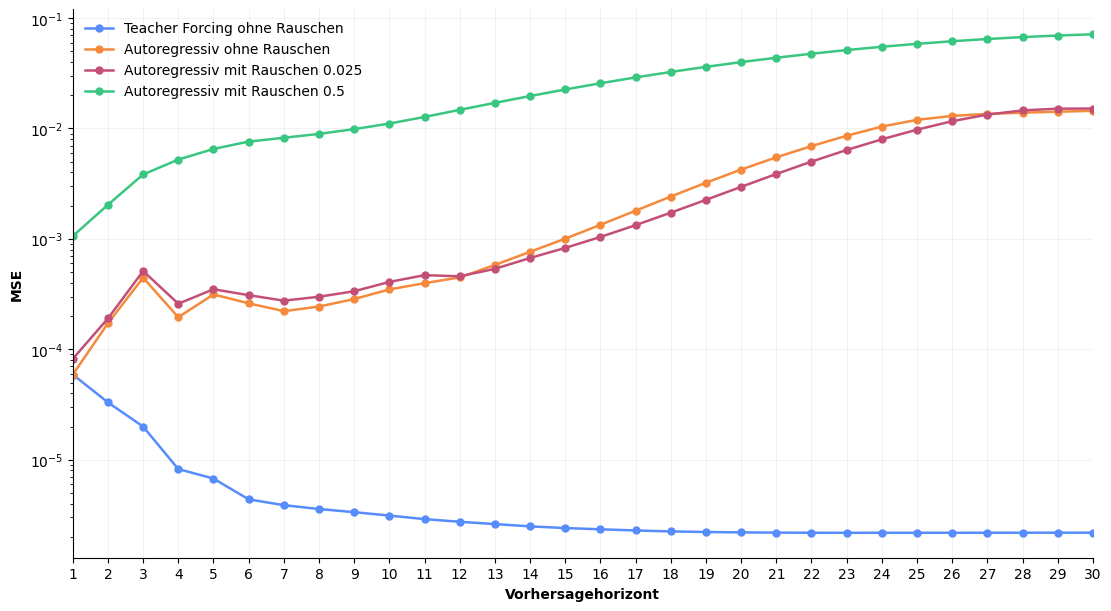

In [24]:
autoreg_ohne_rauschen = [
    5.90802738e-05, 1.72390661e-04, 4.45290614e-04, 1.95374902e-04, 3.14353703e-04,
    2.60910252e-04, 2.21648545e-04, 2.43902716e-04, 2.85384449e-04, 3.48544825e-04,
    3.97375145e-04, 4.47768078e-04, 5.81034285e-04, 7.63829623e-04, 1.00523466e-03,
    1.34123897e-03, 1.80109683e-03, 2.41861073e-03, 3.22654843e-03, 4.24626004e-03,
    5.48014836e-03, 6.92616496e-03, 8.59607756e-03, 1.03978822e-02, 1.19755371e-02,
    1.30020948e-02, 1.35589335e-02, 1.39076188e-02, 1.41849015e-02, 1.44487554e-02
]

autoreg_mit_rauschen_0_5 =[
    0.00105967, 0.00203946, 0.00383236, 0.00523144, 0.00652054, 0.00761119,
    0.00823913, 0.00892916, 0.00986771, 0.01107888, 0.01271748, 0.01475162,
    0.0170618,  0.01967121, 0.02255433, 0.02567067, 0.02899349, 0.03249883,
    0.03615331, 0.03990884, 0.04371466, 0.04752436, 0.05128597, 0.05493805,
    0.05841562, 0.06165631, 0.06460475, 0.06721648, 0.06945903, 0.07131446
]
autoreg_mit_rauschen_0_025 = [
    8.1954e-05, 1.9035e-04, 5.1221e-04, 2.5879e-04, 3.4995e-04,
    3.0944e-04, 2.7589e-04, 2.9948e-04, 3.3575e-04, 4.0770e-04,
    4.6941e-04, 4.5854e-04, 5.3555e-04, 6.7185e-04, 8.2896e-04,
    1.0411e-03, 1.3322e-03, 1.7277e-03, 2.2585e-03, 2.9610e-03,
    3.8712e-03, 5.0120e-03, 6.3852e-03, 7.9760e-03, 9.7590e-03,
    1.1640e-02, 1.3362e-02, 1.4582e-02, 1.5120e-02, 1.5150e-02
]

tf_ohne_rauschen = [
    5.9080274e-05, 3.3080996e-05, 1.9969420e-05, 8.2349616e-06, 6.7552405e-06,
    4.3776727e-06, 3.8800790e-06, 3.5803439e-06, 3.3523058e-06, 3.1235975e-06,
    2.9001012e-06, 2.7441565e-06, 2.6151340e-06, 2.4939122e-06, 2.4070255e-06,
    2.3451760e-06, 2.2889353e-06, 2.2450333e-06, 2.2165307e-06, 2.1991034e-06,
    2.1887420e-06, 2.1828694e-06, 2.1807575e-06, 2.1809792e-06, 2.1818091e-06,
    2.1823450e-06, 2.1831092e-06, 2.1845326e-06, 2.1852941e-06, 2.1863971e-06
]

x = range(1, 31)

fig, ax = plt.subplots(figsize=(11, 6), layout="constrained")

ax.plot(
    x, tf_ohne_rauschen,
    marker="o",
    markersize=5,
    linewidth=1.8,
    label="Teacher Forcing ohne Rauschen"
)
ax.plot(
    x, autoreg_ohne_rauschen,
    marker="o",
    markersize=5,
    linewidth=1.8,
    label="Autoregressiv ohne Rauschen"
)
ax.plot(
    x, autoreg_mit_rauschen_0_025,
    marker="o",
    markersize=5,
    linewidth=1.8,
    label="Autoregressiv mit Rauschen 0.025"
)
ax.plot(
    x, autoreg_mit_rauschen_0_5,
    marker="o",
    markersize=5,
    linewidth=1.8,
    label="Autoregressiv mit Rauschen 0.5"
)

ax.set_yscale("log")
ax.set_ylabel("MSE",  fontweight='bold')

ax.set_xlim(1, 30)
ax.set_xticks(x)
ax.set_xlabel("Vorhersagehorizont",  fontweight='bold')


ax.grid(True, which="major", alpha=0.22)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")

# Diagramm speichern
fig.savefig("Neue_Bilder/mse_autoreg.pdf", dpi=200)


plt.show()

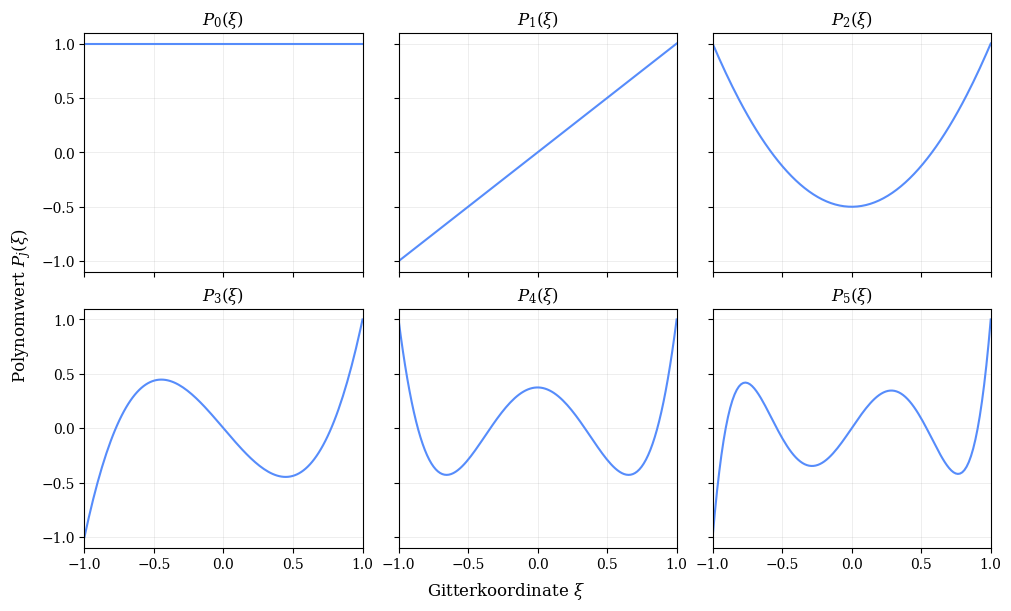

In [3]:
"""Die sechs Legendre-Moden der 128-dimensionalen Lorenz-Beobachtungen."""

import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial.legendre import legvander

# Identisch zur Konstruktion der Modenmatrix im Notebook:
grid = np.linspace(-1, 1, 128)
U = legvander(grid, 5)  # Spalten: P_0 bis P_5, Form (128, 6)

fig, axes = plt.subplots(
    2, 3, figsize=(10, 6),
    sharex=True, sharey=True,
    constrained_layout=True
)

for j, ax in enumerate(axes.flat):
    ax.plot(grid, U[:, j], linewidth=1.5)
    ax.set_title(rf"$P_{{{j}}}(\xi)$")
    ax.set_xlim(-1, 1)
    ax.set_ylim(-1.1, 1.1)
    ax.grid(alpha=0.3)

fig.supxlabel(r"Gitterkoordinate $\xi$")
fig.supylabel(r"Polynomwert $P_j(\xi)$")

plt.savefig("legendre_polynome.pdf", bbox_inches="tight")
plt.show()
